In [5]:
!pip install -q ultralytics pandas matplotlib pillow pyyaml

import os
import shutil
import torch
import yaml
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from ultralytics import YOLO
from google.colab import drive

print("Libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Libraries imported successfully!


In [ ]:
drive.mount("/content/drive")

print("GPU available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("Please enable GPU in Colab.")

print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU available: True
GPU: Tesla T4


In [ ]:
from pathlib import Path

train_dir = Path(
    "/content/drive/MyDrive/VisDrone2019-DET-train/VisDrone2019-DET-train"
)

val_dir = Path(
    "/content/drive/MyDrive/VisDrone2019-DET-val/VisDrone2019-DET-val"
)

for folder in [train_dir, val_dir]:
    assert (folder / "images").is_dir(), f"Images missing: {folder}"
    assert (folder / "annotations").is_dir(), f"Annotations missing: {folder}"

print("Training images:",
      len(list((train_dir / "images").glob("*.jpg"))))

print("Validation images:",
      len(list((val_dir / "images").glob("*.jpg"))))

print("Step 3 completed!")

Training images: 6471
Validation images: 548
Step 3 completed!


In [ ]:


from pathlib import Path
from PIL import Image

def convert_visdrone(dataset_dir):

    images_dir = dataset_dir / "images"
    annotations_dir = dataset_dir / "annotations"
    labels_dir = dataset_dir / "labels"

    # Create labels folder
    labels_dir.mkdir(parents=True, exist_ok=True)

    converted = 0

    # Process each image
    for image_path in images_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        # Get image dimensions
        with Image.open(image_path) as img:
            img_width, img_height = img.size

        annotation_path = annotations_dir / (image_path.stem + ".txt")
        label_path = labels_dir / (image_path.stem + ".txt")

        yolo_labels = []

        # Read original annotations
        if annotation_path.exists():

            with open(annotation_path, "r") as f:
                lines = f.readlines()

            for line in lines:

                values = line.strip().split(",")

                if len(values) < 6:
                    continue

                x, y, w, h = map(float, values[:4])
                category = int(values[5])

                # Skip ignored regions and invalid categories
                if category < 1 or category > 10:
                    continue

                if w <= 0 or h <= 0:
                    continue

                # Clip bounding box to image boundaries
                x1 = max(0, min(x, img_width))
                y1 = max(0, min(y, img_height))
                x2 = max(0, min(x + w, img_width))
                y2 = max(0, min(y + h, img_height))

                if x2 <= x1 or y2 <= y1:
                    continue

                # Convert to normalized YOLO coordinates
                x_center = (x1 + x2) / (2 * img_width)
                y_center = (y1 + y2) / (2 * img_height)
                box_width = (x2 - x1) / img_width
                box_height = (y2 - y1) / img_height

                # YOLO class IDs start from 0
                class_id = category - 1

                yolo_labels.append(
                    f"{class_id} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{box_width:.6f} "
                    f"{box_height:.6f}"
                )

        # Save YOLO labels
        with open(label_path, "w") as f:
            f.write("\n".join(yolo_labels))

        converted += 1

        if converted % 500 == 0:
            print(f"{dataset_dir.name}: {converted} images processed")

    print(f"\nCompleted: {dataset_dir.name}")
    print(f"Total images converted: {converted}")
    print(f"Labels saved to: {labels_dir}")


# Convert training dataset
convert_visdrone(train_dir)

# Convert validation dataset
convert_visdrone(val_dir)

print("\nSTEP 4 COMPLETED!")


KeyboardInterrupt: 

In [ ]:
from pathlib import Path

for folder in [train_dir, val_dir]:
    labels_dir = folder / "labels"

    if labels_dir.exists():
        count = len(list(labels_dir.glob("*.txt")))
        print(folder.name, ":", count, "labels generated")
    else:
        print(folder.name, ": labels folder not created")

VisDrone2019-DET-train : 6471 labels generated
VisDrone2019-DET-val : 548 labels generated


In [ ]:
from pathlib import Path

train_dir = Path("/content/drive/MyDrive/VisDrone2019-DET-train/VisDrone2019-DET-train")
val_dir = Path("/content/drive/MyDrive/VisDrone2019-DET-val/VisDrone2019-DET-val")

train_count = len(list((train_dir / "labels").glob("*.txt")))
val_count = len(list((val_dir / "labels").glob("*.txt")))

print("Train:", train_count, "/6471")
print("Val:", val_count, "/548")
print("Total:", train_count + val_count, "/7019")

Train: 6471 /6471
Val: 548 /548
Total: 7019 /7019


In [ ]:

import yaml
from pathlib import Path

# 10 object categories in VisDrone
classes = [
    "pedestrian",
    "people",
    "bicycle",
    "car",
    "van",
    "truck",
    "tricycle",
    "awning-tricycle",
    "bus",
    "motor"
]

# Dataset configuration
dataset_config = {
    "train": str(train_dir / "images"),
    "val": str(val_dir / "images"),
    "nc": 10,
    "names": classes
}

# Save YAML configuration
yaml_path = Path("/content/visdrone.yaml")

with open(yaml_path, "w") as f:
    yaml.safe_dump(dataset_config, f, sort_keys=False)

# Display configuration
print(yaml_path.read_text())
print("\nSTEP 5 COMPLETED!")


train: /content/drive/MyDrive/VisDrone2019-DET-train/VisDrone2019-DET-train/images
val: /content/drive/MyDrive/VisDrone2019-DET-val/VisDrone2019-DET-val/images
nc: 10
names:
- pedestrian
- people
- bicycle
- car
- van
- truck
- tricycle
- awning-tricycle
- bus
- motor


STEP 5 COMPLETED!


In [ ]:

from ultralytics import YOLO
from pathlib import Path

model = YOLO("yolo11n.pt")

model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/runs",
    name="baseline",
    exist_ok=True,
    plots=True,
    seed=42,
    save=True,
    save_period=5
)

run_dir = Path("/content/runs/baseline")

print("STEP 6 COMPLETED!")
print("Results saved to:", run_dir)


Ultralytics 8.4.209 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/visdrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

KeyboardInterrupt: 

参数	当前值	来源
yolo11n.pt	YOLO11 Nano epochs	50	imgaze	640
batch	8	device 0 workers	2

In [ ]:

from pathlib import Path
import shutil

# Google Drive destination
project = Path("/content/drive/MyDrive/401 Project")
project.mkdir(parents=True, exist_ok=True)

# STEP 4: Save all converted labels
train_labels = Path("/content/drive/MyDrive/VisDrone2019-DET-train/VisDrone2019-DET-train/labels")
val_labels = Path("/content/drive/MyDrive/VisDrone2019-DET-val/VisDrone2019-DET-val/labels")

shutil.copytree(
    train_labels,
    project / "Step4" / "train_labels",
    dirs_exist_ok=True
)

shutil.copytree(
    val_labels,
    project / "Step4" / "val_labels",
    dirs_exist_ok=True
)

# STEP 6: Save trained model and all training results
run_source = Path("/content/runs/baseline")

if not run_source.exists():
    raise FileNotFoundError(
        "Step 6 results not found at /content/runs/baseline. Check your training output path."
    )

shutil.copytree(
    run_source,
    project / "Step6" / "baseline",
    dirs_exist_ok=True
)

# STEP 5: Save dataset configuration
yaml_source = Path("/content/visdrone.yaml")

if yaml_source.exists():
    shutil.copy2(yaml_source, project / "visdrone.yaml")

# Verify saved files
train_count = len(list((project / "Step4/train_labels").glob("*.txt")))
val_count = len(list((project / "Step4/val_labels").glob("*.txt")))

print("Train labels saved:", train_count, "/ 6471")
print("Val labels saved:", val_count, "/ 548")
print("Best model saved:", (project / "Step6/baseline/weights/best.pt").exists())
print("Last model saved:", (project / "Step6/baseline/weights/last.pt").exists())
print("Training CSV saved:", (project / "Step6/baseline/results.csv").exists())
print("Google Drive folder:", project)


KeyboardInterrupt: 

这是存代码的

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


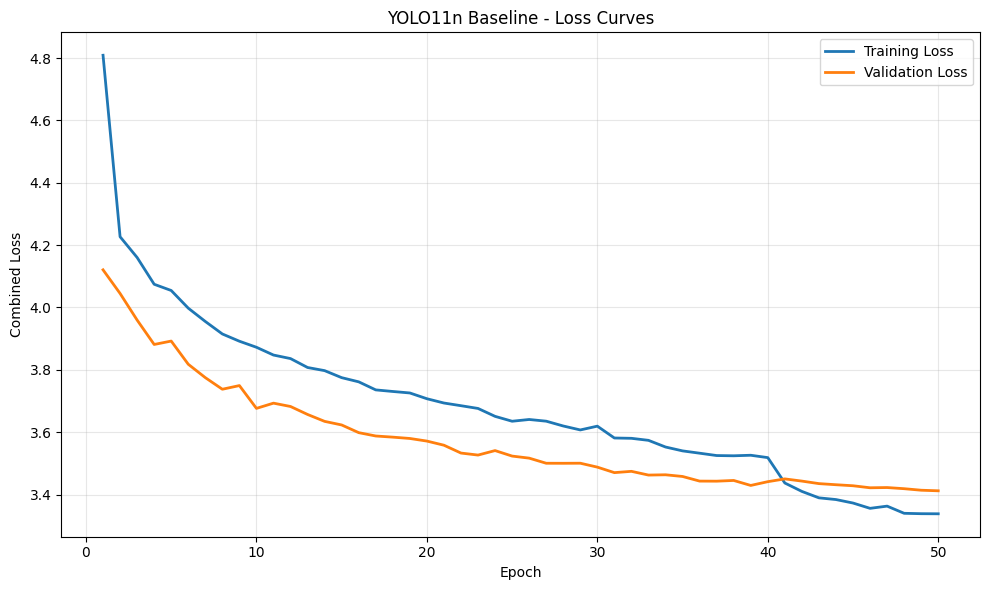


YOLO11n BASELINE RESULTS
Selected Epoch: 50
   Metric  Value
      mAP 0.1733
Precision 0.4420
   Recall 0.3222

Step 7 Completed!
Results saved to: /content/drive/MyDrive/401 Project/Step7


In [ ]:

# ============================================================
# CMPE 401 - STEP 7: Baseline Results
# Model: YOLO11n
# Dataset: VisDrone2019-DET
#
# Outputs:
# 1. Training Loss
# 2. Validation Loss
# 3. mAP
# 4. Precision
# 5. Recall
#
# No retraining
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# STEP 7.1 - Load existing Step 6 results
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/401 Project")
CSV_PATH = BASE / "Step6/baseline/results.csv"
OUTPUT = BASE / "Step7"

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Training results not found: {CSV_PATH}"
    )

OUTPUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip()

# Required columns
required = [
    "train/box_loss",
    "train/cls_loss",
    "train/dfl_loss",
    "val/box_loss",
    "val/cls_loss",
    "val/dfl_loss",
    "metrics/mAP50-95(B)",
    "metrics/precision(B)",
    "metrics/recall(B)"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

epochs = (
    df["epoch"]
    if "epoch" in df.columns
    else range(1, len(df) + 1)
)

# STEP 7.2 - Training and Validation Loss
# Combined loss = Box + Classification + DFL

training_loss = (
    df["train/box_loss"]
    + df["train/cls_loss"]
    + df["train/dfl_loss"]
)

validation_loss = (
    df["val/box_loss"]
    + df["val/cls_loss"]
    + df["val/dfl_loss"]
)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    training_loss,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs,
    validation_loss,
    label="Validation Loss",
    linewidth=2
)

plt.title("YOLO11n Baseline - Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Combined Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT / "loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# STEP 7.3 - mAP, Precision, Recall
# Select epoch with highest mAP50-95

best_index = df["metrics/mAP50-95(B)"].idxmax()
best = df.loc[best_index]

mAP = best["metrics/mAP50-95(B)"]
precision = best["metrics/precision(B)"]
recall = best["metrics/recall(B)"]

results = pd.DataFrame({
    "Metric": ["mAP", "Precision", "Recall"],
    "Value": [mAP, precision, recall]
})

print("\n==============================")
print("YOLO11n BASELINE RESULTS")
print("==============================")

print(
    "Selected Epoch:",
    int(best["epoch"])
    if "epoch" in df.columns
    else best_index + 1
)

print(results.to_string(
    index=False,
    float_format="%.4f"
))

# STEP 7.4 - Save results
results.to_csv(
    OUTPUT / "baseline_metrics.csv",
    index=False
)

print("\nStep 7 Completed!")
print("Results saved to:", OUTPUT)


In [ ]:

from ultralytics import YOLO
from pathlib import Path

# Experiment 1: Higher image resolution
model = YOLO("yolo11n.pt")

model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=960,          # Changed: 640 -> 960
    batch=8,
    device=0,
    workers=2,
    project="/content/runs",
    name="experiment_img960",
    exist_ok=True,
    plots=True,
    seed=42,
    save=True,
    save_period=5
)

run_dir = Path("/content/runs/experiment_img960")

print("EXPERIMENT 1 COMPLETE!")
print("Results saved to:", run_dir)


Ultralytics 8.4.209 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/visdrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment_img960, nbs=64, nms=None, opset=None, optimize=False, op

In [ ]:

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

baseline_path = Path(
    "/content/drive/MyDrive/401 Project/Step6/baseline/results.csv"
)

experiment_path = Path(
    "/content/runs/experiment_img960/results.csv"
)

print("Baseline exists:", baseline_path.exists())
print("Experiment exists:", experiment_path.exists())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Baseline exists: True
Experiment exists: True


In [ ]:

import pandas as pd

# Read results
baseline = pd.read_csv(baseline_path)
experiment = pd.read_csv(experiment_path)

# Clean column names
baseline.columns = baseline.columns.str.strip()
experiment.columns = experiment.columns.str.strip()

# Compare three metrics
metrics = {
    "Precision": "metrics/precision(B)",
    "Recall": "metrics/recall(B)",
    "mAP50-95": "metrics/mAP50-95(B)"
}

results = []

for metric, col in metrics.items():
    b = baseline[col].iloc[-1]
    e = experiment[col].iloc[-1]

    results.append({
        "Metric": metric,
        "Baseline (640)": round(b, 4),
        "Experiment (960)": round(e, 4),
        "Difference": round(e - b, 4)
    })

comparison = pd.DataFrame(results)

display(comparison)


,Metric,Baseline (640),Experiment (960),Difference
0,Precision,0.4420,0.5187,0.0768
1,Recall,0.3222,0.4025,0.0803
2,mAP50-95,0.1733,0.2406,0.0673


In [ ]:

from google.colab import drive
from pathlib import Path
import shutil

# Mount Google Drive
drive.mount("/content/drive")

# Experiment 1 training results
source = Path("/content/runs/experiment_img960")

# Save to Google Drive
destination = Path(
    "/content/drive/MyDrive/401 Project/Experiment1_img960"
)

# Check source
if not source.exists():
    raise FileNotFoundError(f"Source not found: {source}")

# Copy all training results
shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)

print("EXPERIMENT 1 SAVED!")
print("Location:", destination)

# Verify important files
for filename in [
    "results.csv",
    "results.png",
    "weights/best.pt",
    "weights/last.pt"
]:
    file = destination / filename
    print(filename, ":", file.exists())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EXPERIMENT 1 SAVED!
Location: /content/drive/MyDrive/401 Project/Experiment1_img960
results.csv : True
results.png : True
weights/best.pt : True
weights/last.pt : True


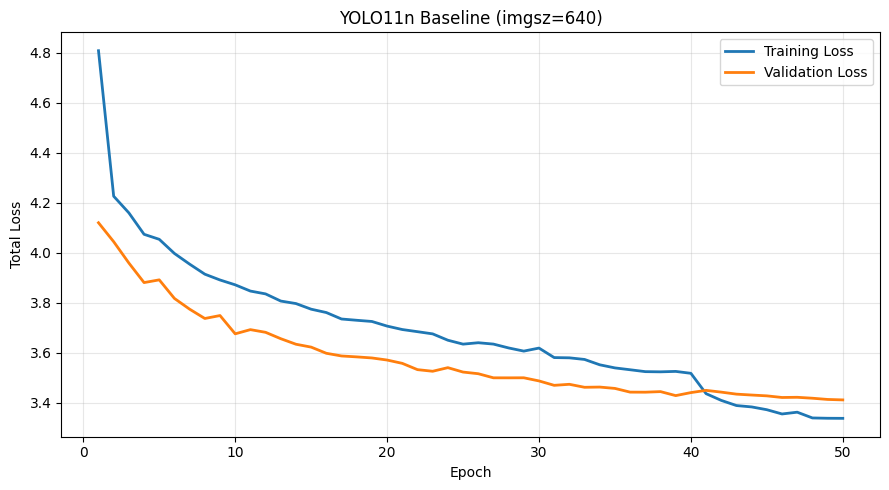

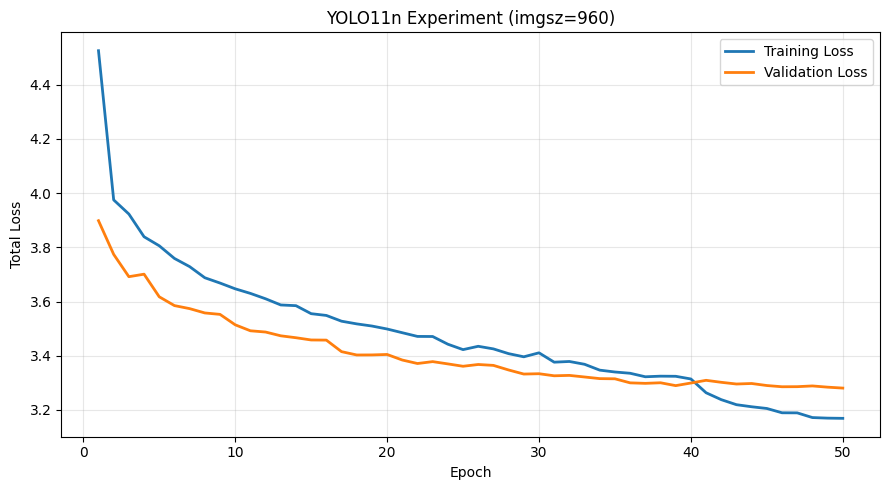

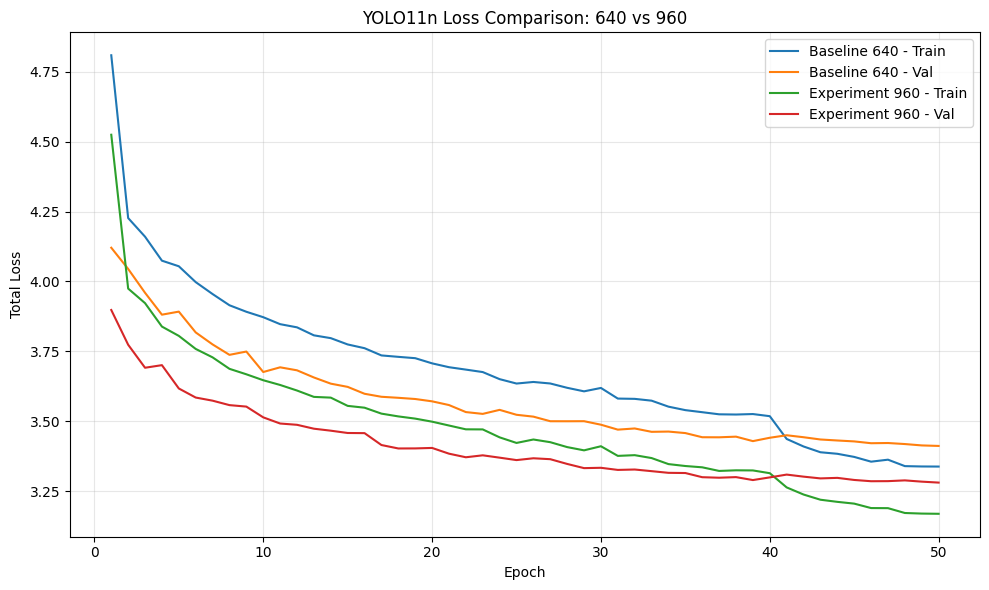

All loss plots saved to: /content/drive/MyDrive/401 Project/Loss_Comparison


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =========================================
# 1. File paths
# =========================================

baseline_path = Path(
    "/content/drive/MyDrive/401 Project/Step6/baseline/results.csv"
)

experiment_path = Path(
    "/content/drive/MyDrive/401 Project/Experiment1_img960/results.csv"
)

output_dir = Path(
    "/content/drive/MyDrive/401 Project/Loss_Comparison"
)
output_dir.mkdir(parents=True, exist_ok=True)

# =========================================
# 2. Load training results
# =========================================

def load_losses(path):
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    df["train_total"] = (
        df["train/box_loss"] +
        df["train/cls_loss"] +
        df["train/dfl_loss"]
    )

    df["val_total"] = (
        df["val/box_loss"] +
        df["val/cls_loss"] +
        df["val/dfl_loss"]
    )

    return df

baseline = load_losses(baseline_path)
experiment = load_losses(experiment_path)

# =========================================
# 3. Plot each experiment
# =========================================

def plot_loss(df, title, filename):
    plt.figure(figsize=(9, 5))

    plt.plot(
        df["epoch"],
        df["train_total"],
        label="Training Loss",
        linewidth=2
    )

    plt.plot(
        df["epoch"],
        df["val_total"],
        label="Validation Loss",
        linewidth=2
    )

    plt.xlabel("Epoch")
    plt.ylabel("Total Loss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(output_dir / filename, dpi=300)
    plt.show()

plot_loss(
    baseline,
    "YOLO11n Baseline (imgsz=640)",
    "baseline_loss.png"
)

plot_loss(
    experiment,
    "YOLO11n Experiment (imgsz=960)",
    "experiment_loss.png"
)

# =========================================
# 4. Compare both experiments
# =========================================

plt.figure(figsize=(10, 6))

plt.plot(
    baseline["epoch"],
    baseline["train_total"],
    label="Baseline 640 - Train"
)

plt.plot(
    baseline["epoch"],
    baseline["val_total"],
    label="Baseline 640 - Val"
)

plt.plot(
    experiment["epoch"],
    experiment["train_total"],
    label="Experiment 960 - Train"
)

plt.plot(
    experiment["epoch"],
    experiment["val_total"],
    label="Experiment 960 - Val"
)

plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.title("YOLO11n Loss Comparison: 640 vs 960")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "loss_comparison.png",
    dpi=300
)

plt.show()

print("All loss plots saved to:", output_dir)
